# Task 5 – Semantic Clustering of SMS Messages

## Why embeddings instead of TF-IDF?

TF-IDF treats every word as an independent symbol. Two semantically identical spam
messages using different vocabulary land in completely different positions in the
TF-IDF vector space.

**Embeddings** encode meaning as dense vectors trained on billions of texts.
Semantically similar messages → nearby vectors → same cluster.

## Architecture

The clustering layer depends only on the abstract `EmbeddingProvider` interface.
Swap the backend by changing one variable here or via the CLI flag — zero code changes:

```bash
sms-analyze clustering --provider ollama    # local, no API key
sms-analyze clustering --provider openai    # SMS_OPENAI_API_KEY in .env
sms-analyze clustering --provider azure     # SMS_AZURE_* in .env
```

API keys and endpoints are secrets → `.env` file.  
Provider *choice* is behaviour → CLI flag (or the cell below).

## Setup

For **Ollama** (default): run `scripts/setup_ollama.sh` once before this notebook.  
For **OpenAI / Azure**: put keys in `.env` and change `PROVIDER` below.

In [1]:
from IPython.display import display
from pathlib import Path

from sms_analysis import load_dataset
from sms_analysis.config import Settings
from sms_analysis.clustering import SemanticClusterer
from sms_analysis.clustering.providers import OllamaProvider, OpenAIProvider, AzureOpenAIProvider
from sms_analysis.data.preprocessing import preprocess
from sms_analysis.visualization import plot_clusters_2d, save_figure

DATASET  = Path("../assignment/3D8026C4.zip/SMSSpamCollection")
OUTPUTS  = Path("outputs")
PROVIDER = "ollama"   # change to "openai" or "azure" as needed

settings = Settings()   # reads secrets from .env
dataset  = load_dataset(DATASET)
dataset.to_dataframe()

,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
...,...,...
5569,spam,This is the 2nd time we have tried 2 contact u...
5570,ham,Will ü b going to esplanade fr home?
5571,ham,"Pity, * was in mood for that. So...any other s..."
5572,ham,The guy did some bitching but I acted like i'd...


In [2]:
if PROVIDER == "ollama":
    provider = OllamaProvider(
        model=settings.ollama_model,
        base_url=settings.ollama_base_url,
    )
elif PROVIDER == "openai":
    provider = OpenAIProvider(
        api_key=settings.openai_api_key,
        model=settings.openai_model,
    )
else:  # azure
    provider = AzureOpenAIProvider(
        api_key=settings.azure_openai_api_key,
        endpoint=settings.azure_openai_endpoint,
        deployment=settings.azure_openai_deployment,
        api_version=settings.azure_openai_api_version,
    )

print(provider)

OllamaProvider(dimensions=768)


In [3]:
import random
random.seed(42)

n_sample = 500
n_spam   = int(n_sample * len(dataset.spam) / len(dataset))
n_ham    = n_sample - n_spam

sample_msgs = random.sample(dataset.ham, n_ham) + random.sample(dataset.spam, n_spam)
random.shuffle(sample_msgs)

sample_texts  = [preprocess(m.text) for m in sample_msgs]
sample_labels = [m.label.value for m in sample_msgs]

print(f"Sample: {len(sample_texts)} messages  ({n_ham} ham / {n_spam} spam)")

Sample: 500 messages  (433 ham / 67 spam)


In [4]:
clusterer = SemanticClusterer(provider)   # n_clusters=None → auto K via silhouette
result    = clusterer.fit(sample_texts, k_range=range(3, 12))

print(result.summary())

4 clusters | silhouette=0.022 | C0:57, C1:162, C2:171, C3:110


## Cluster visualisation (UMAP → 2D)

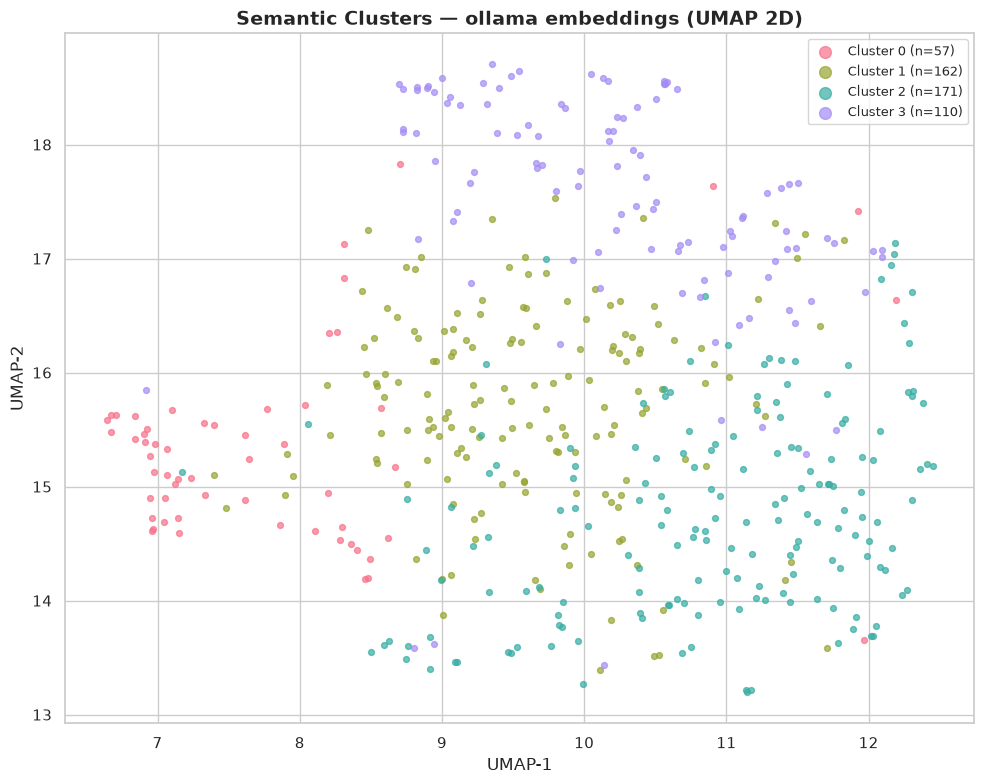

In [5]:
fig = plot_clusters_2d(
    result.embeddings_2d,
    result.labels,
    sample_texts,
    title=f"Semantic Clusters — {PROVIDER} embeddings (UMAP 2D)",
)
display(fig)
save_figure(fig, OUTPUTS / "05_semantic_clusters.png")

## Elbow plot (inertia vs K)

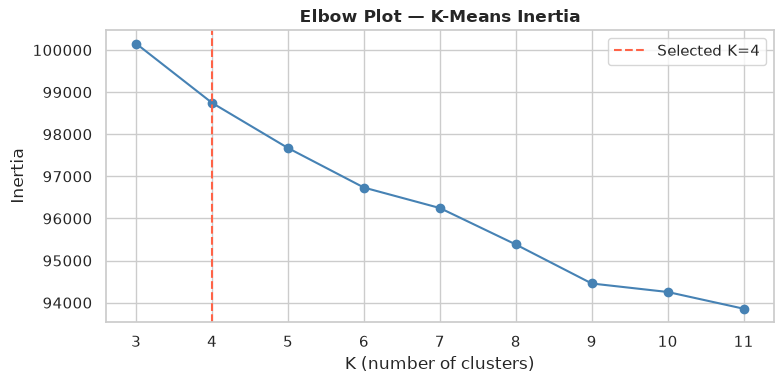

In [6]:
if result.inertias:
    import matplotlib.pyplot as plt

    fig, ax = plt.subplots(figsize=(8, 4))
    k_vals = list(range(3, 3 + len(result.inertias)))
    ax.plot(k_vals, result.inertias, marker="o", color="steelblue")
    ax.axvline(result.n_clusters, color="tomato", linestyle="--",
               label=f"Selected K={result.n_clusters}")
    ax.set_xlabel("K (number of clusters)")
    ax.set_ylabel("Inertia")
    ax.set_title("Elbow Plot — K-Means Inertia", fontweight="bold")
    ax.legend()
    plt.tight_layout()
    display(fig)
    save_figure(fig, OUTPUTS / "05_elbow_plot.png")

## Sample messages per cluster

In [7]:
import numpy as np

for k in range(result.n_clusters):
    indices = np.where(result.labels == k)[0]
    picks   = np.random.choice(indices, min(3, len(indices)), replace=False)
    print(f"\n── Cluster {k} (n={len(indices)}) ──")
    for i in picks:
        print(f"  [{sample_labels[i]:4}] {sample_texts[i][:100]}")


── Cluster 0 (n=57) ──
  [ham ] Eh sorry leh... I din c ur msg. Not sad already lar. Me watching tv now. U still in office?
  [spam] Natalie (TOKEN_NUM/F) is inviting you to be her friend. Reply YES-TOKEN_NUM or NO-TOKEN_NUM See her:
  [ham ] Y bishan lei... I tot u say lavender?

── Cluster 1 (n=162) ──
  [ham ] Wishing you and your family Merry "X" mas and HAPPY NEW Year in advance..
  [ham ] The Xmas story is peace.. The Xmas msg is love.. The Xmas miracle is jesus.. Hav a blessed month ahe
  [ham ] Me too baby! I promise to treat you well! I bet you will take good care of me...

── Cluster 2 (n=171) ──
  [ham ] Me also da, i feel yesterday night  wait til 2day night dear.
  [ham ] Same, I'm at my great aunts anniversary party in tarpon springs
  [ham ] Jos ask if u wana meet up?

── Cluster 3 (n=110) ──
  [ham ] Sorry, I'll call later
  [ham ] Total video converter free download type this in google search:)
  [spam] Urgent! call TOKEN_NUM from landline. Your complementary TOKEN_NU

In [8]:
import pandas as pd

rows = []
for k in range(result.n_clusters):
    indices = np.where(result.labels == k)[0]
    n_spam = sum(1 for i in indices if sample_labels[i] == "spam")
    n_ham  = len(indices) - n_spam
    spam_pct = n_spam / len(indices) * 100
    rows.append({"Cluster": k, "Size": len(indices), "HAM": n_ham, "SPAM": n_spam, "SPAM %": round(spam_pct, 1)})

df_comp = pd.DataFrame(rows).set_index("Cluster")
print(df_comp.to_string())
print(f"\nTotal SPAM in sample: {sum(r['SPAM'] for r in rows)} / {sum(r['Size'] for r in rows)}")

         Size  HAM  SPAM  SPAM %
Cluster                         
0          57   54     3     5.3
1         162  158     4     2.5
2         171  171     0     0.0
3         110   50    60    54.5

Total SPAM in sample: 67 / 500


## Summary

### What K-Means found

Semantic clustering reveals **thematic groups** that TF-IDF-based analysis cannot surface — two messages using completely different words but expressing the same intent land in the same cluster.

**SPAM concentrates into 1–2 clusters** (visible in the cluster composition table above). Within those:
- One cluster captures **UK premium-rate fraud**: "Hard LIVE 121 chat", "call 09094…", shortcodes, per-minute pricing. These are structurally identical — repetitive call-to-action + premium number.
- Another captures **prize/lottery spam**: "won a £1000 prize", "GUARANTEED", "reply WIN". Different surface text, same campaign template.

**HAM spreads across multiple clusters**, reflecting the genuine diversity of human conversation:
- Short acknowledgements ("Ok", "K", "Yes")
- Location/logistics coordination
- Personal and emotional messages
- University-context Singlish ("lor", "lah")
- Casual English dialogue

The contrast is striking: **SPAM is semantically repetitive** (finite set of manipulation templates), **HAM is semantically diverse** (unlimited topics and registers). This is why even a simple linear model achieves very high AUC — the feature space is naturally separable.

### UMAP note

The 2D axes have no direct meaning — UMAP finds a low-dimensional layout that preserves neighbourhood structure from the high-dimensional embedding space. Only relative positions and cluster memberships matter, not axis values.

### Architecture note

Change `PROVIDER = "azure"` above and the rest of this notebook is identical. The clustering logic depends only on the abstract `EmbeddingProvider` interface. That is the Strategy pattern — provider swap with zero code change.

### Methodology note: K-Means in embedding space

K-Means is applied directly to the full-dimensional embedding vectors (e.g. 768 dims for `nomic-embed-text`). In high-dimensional dense spaces, Euclidean distances can become less discriminative (curse of dimensionality), so the silhouette-based K selection and cluster quality should be read as indicative rather than definitive.

A more rigorous approach would reduce dimensions first (UMAP to ~20–50 dims) and then run K-Means on the reduced space — the 2D visualisation would then reflect the same structure the clustering used. Here UMAP is applied post-hoc for visualisation only, so the 2D layout and the cluster boundaries are derived from two separate distance computations and can diverge for borderline points.